In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("housing.csv")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (20640, 10)

Column Names:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)

In [3]:
# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values with the median
df["total_bedrooms"] = df["total_bedrooms"].fillna(
    df["total_bedrooms"].median()
)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [4]:
# Statistical summary of the dataset
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


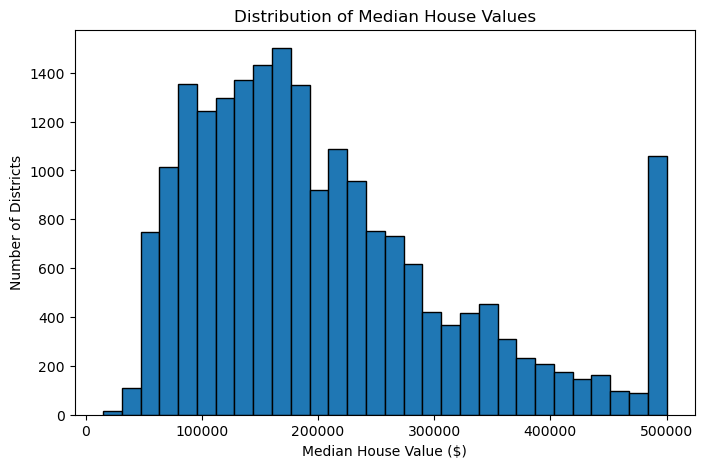

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["median_house_value"], bins=30, edgecolor="black")

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Number of Districts")

plt.show()

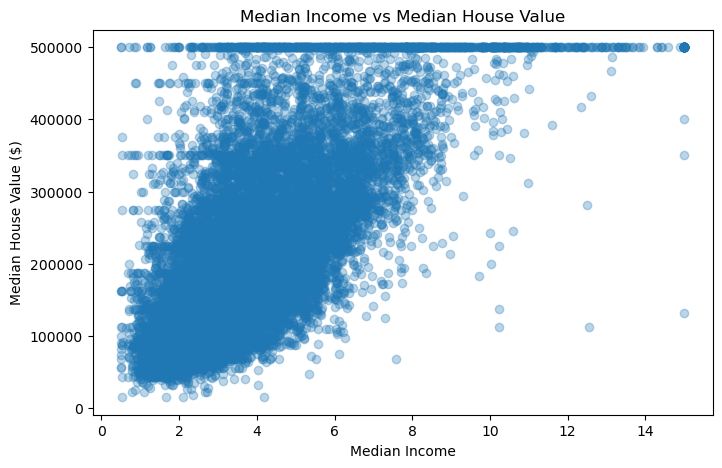

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["median_income"],
    df["median_house_value"],
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($)")

plt.show()

In [7]:
print(df["ocean_proximity"].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [8]:
df_encoded = pd.get_dummies(
    df,
    columns=["ocean_proximity"],
    dtype=int
)

df_encoded.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


In [9]:
# Separate features and target
X = df_encoded.drop("median_house_value", axis=1)
y = df_encoded["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 13)
Target shape: (20640,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 13)
Testing data: (4128, 13)


In [11]:
X = df_encoded.drop("median_house_value", axis=1)
y = df_encoded["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 13)
Target shape: (20640,)


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 13)
Testing data: (4128, 13)


In [13]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [14]:
# Predict house prices
y_pred = model.predict(X_test)

# Display actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

comparison

,Actual Price,Predicted Price
0,47700.0,54055.448899
1,45800.0,124225.338937
2,500001.0,255489.379492
3,218600.0,268002.431569
4,278000.0,262769.434816
5,158700.0,139606.303956
6,198200.0,290665.423914
7,157500.0,228264.876375
8,340000.0,256506.785610
9,446600.0,407923.858435


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))
print("R² Score (%):", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 50670.74
Mean Squared Error (MSE): 4908476721.16
Root Mean Squared Error (RMSE): 70060.52
R² Score: 0.6254
R² Score (%): 62.54 %


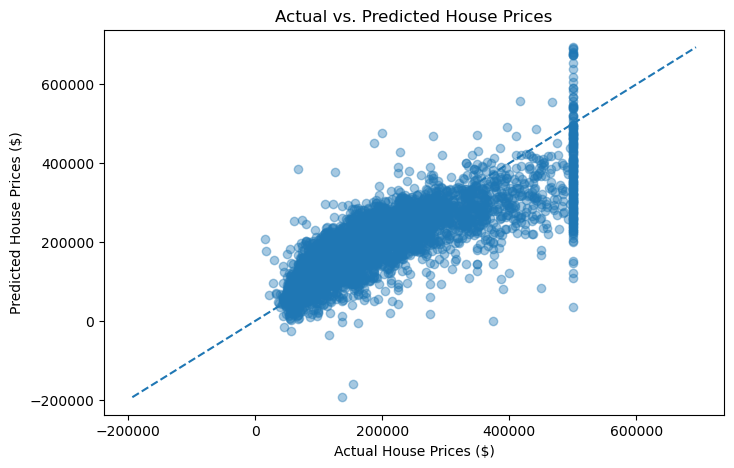

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")
plt.title("Actual vs. Predicted House Prices")

# Reference line for perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.show()

In [17]:
from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree model
dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [18]:
# Predict house prices using Decision Tree
y_pred_dt = dt_model.predict(X_test)

# Compare actual and predicted prices
comparison_dt = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred_dt[:10]
})

comparison_dt

,Actual Price,Predicted Price
0,47700.0,61206.329114
1,45800.0,66479.545455
2,500001.0,439405.000000
3,218600.0,227714.084507
4,278000.0,206504.050000
5,158700.0,163056.382979
6,198200.0,204294.267516
7,157500.0,174800.906344
8,340000.0,260569.596958
9,446600.0,488239.230769


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Evaluation Results")
print("--------------------------------")
print("MAE:", round(mae_dt, 2))
print("MSE:", round(mse_dt, 2))
print("RMSE:", round(rmse_dt, 2))
print("R² Score:", round(r2_dt, 4))
print("R² Score (%):", round(r2_dt * 100, 2), "%")

Decision Tree Evaluation Results
--------------------------------
MAE: 40566.39
MSE: 3748810603.59
RMSE: 61227.53
R² Score: 0.7139
R² Score (%): 71.39 %


In [20]:
# Compare Linear Regression and Decision Tree

comparison_results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [mae, mae_dt],
    "MSE": [mse, mse_dt],
    "RMSE": [rmse, rmse_dt],
    "R2 Score": [r2, r2_dt]
})

comparison_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,50670.738241,4.908477e+09,70060.521845,0.625424
1,Decision Tree,40566.392564,3.748811e+09,61227.531418,0.713921


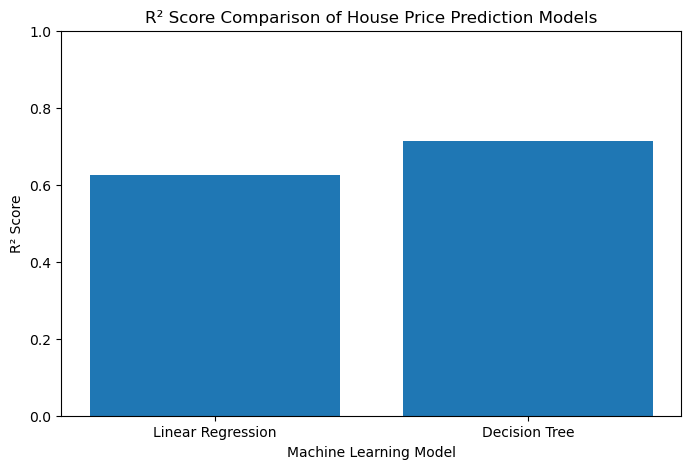

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["R2 Score"]
)

plt.title("R² Score Comparison of House Price Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)

plt.show()

In [22]:
# Get feature importance from the Decision Tree model
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": dt_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
7,median_income,0.563233
9,ocean_proximity_INLAND,0.172734
0,longitude,0.092478
1,latitude,0.081478
2,housing_median_age,0.042770
4,total_bedrooms,0.013596
5,population,0.010863
12,ocean_proximity_NEAR OCEAN,0.008144
6,households,0.007985
3,total_rooms,0.005976


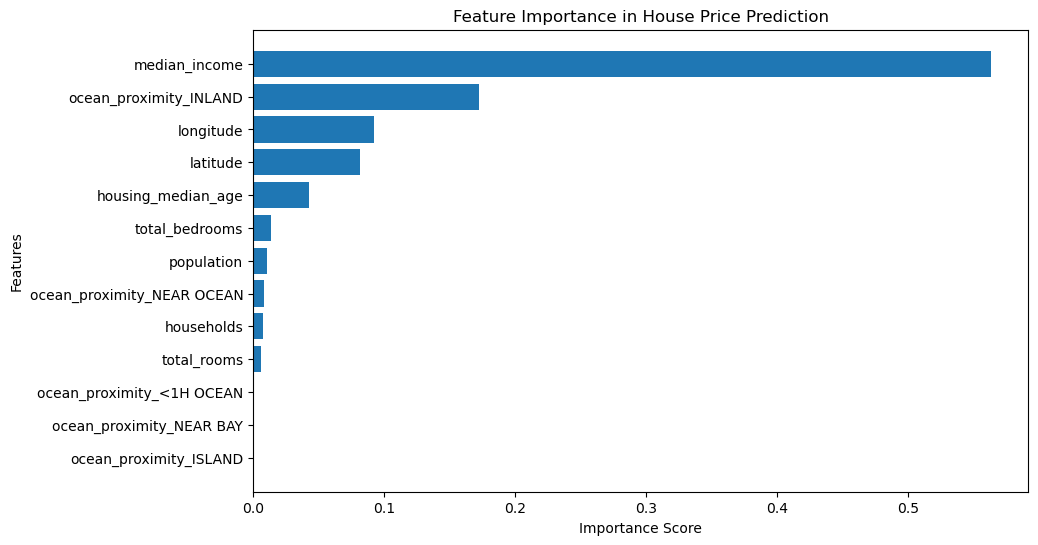

In [23]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance in House Price Prediction")
plt.gca().invert_yaxis()

plt.show()

### Conclusion

In this project, I developed machine learning models to predict house prices using the California housing dataset, which contains 20,640 records and 10 original columns.

The dataset was explored and cleaned by handling missing values in the `total_bedrooms` column. The categorical feature `ocean_proximity` was converted into numerical features using One-Hot Encoding.

Two regression models were trained and evaluated: Linear Regression and Decision Tree Regression. The dataset was divided into 80% training data and 20% testing data.

The Decision Tree Regression model achieved an R² score of 0.7139 (71.39%), with an MAE of 40,566.39 and an RMSE of 61,227.53. It performed better than Linear Regression based on the R² score comparison.

Feature importance analysis was also performed to identify which input features contributed most to the Decision Tree's predictions.

This project provided practical experience in data preprocessing, exploratory data analysis, machine learning, model evaluation, and data visualization using Python.

### Key Finding: Median Income

The feature importance analysis identified `median_income` as the most important feature in the Decision Tree Regression model for predicting house prices.

This suggests that median income plays a major role in the model's predictions. Housing districts with different median income levels may have substantially different predicted house values.

This finding highlights the importance of socioeconomic information when estimating housing prices. However, feature importance indicates how the model uses a feature; it does not prove that income directly causes house prices to increase.